# Who is actually trading this stock?

### Broker-level order flow on the Nepal Stock Exchange

Almost every equity market in the world hides who is on the other side of a trade.
US consolidated tape gives you price, size and time, and nothing about identity.
Academic work on broker behaviour usually depends on proprietary regulator data
that most researchers never see.

NEPSE is different. Its floorsheet names **both counterparties on every single
executed contract**, with a microsecond timestamp:

| field | meaning |
|---|---|
| `contract_id` | one executed trade |
| `trade_time` | microsecond resolution |
| `buyer_member_id` / `seller_member_id` | **the two brokers** |
| `contract_quantity` / `contract_rate` / `contract_amount` | size and price |

This notebook asks three questions of that data, in increasing order of ambition:

1. **How concentrated is Nepali brokerage?** Do a handful of firms dominate?
2. **Does broker positioning persist?** If a broker is a large net buyer today,
   are they still buying tomorrow?
3. **Does any of it predict returns?** The question everyone actually wants
   answered.

The third one has an honest answer, and it is not the exciting one.

> **Sample size warning, stated up front.** The tick archive begins 2026-08-19,
> because NEPSE serves the floorsheet only for the current session and wipes it a
> few hours after close — it cannot be backfilled by anyone. At the pinned
> revision this is **5 sessions**. That is plenty for cross-sectional questions
> (1 and 2) and *not* enough for question 3. We will quantify rather than hide it.

## Setup

The dataset is pinned to a specific revision so these numbers stay reproducible as it grows.

In [1]:
import sys; sys.path.insert(0, ".")
from nepse_nb import connect, setup_plots, annotate, npr, BLUE, AQUA, ORANGE, CRIMSON, MUTED, INK, GRID
import matplotlib.pyplot as plt
import numpy as np

setup_plots()
con = connect()

sessions = con.execute("""
    SELECT business_date, count(*) contracts, count(DISTINCT stock_symbol) symbols,
           sum(CAST(contract_amount AS DOUBLE)) turnover
    FROM floorsheet GROUP BY 1 ORDER BY 1
""").df()
print(sessions.to_string(index=False))
print(f"\ntotal contracts: {sessions.contracts.sum():,}")

business_date  contracts  symbols     turnover
   2026-08-19      42709      346 3.298020e+09
   2026-08-20      47919      345 4.401410e+09
   2026-08-21      59805      344 4.167619e+09
   2026-08-24      53153      350 3.239761e+09
   2026-08-25      46589      357 4.109752e+09

total contracts: 250,175


Every one of those contracts carries two broker IDs, so a single session gives us
roughly 100,000 broker-trade observations.

## 1. How concentrated is Nepali brokerage?

The intuition for a frontier market is that a few connected firms dominate. Let's
check rather than assume.

We measure each broker's **turnover participation**: the value they traded,
counting both the buy and the sell side, since a broker is equally "active" either
way. Then the Herfindahl-Hirschman Index (HHI) — the sum of squared percentage
shares. It ranges from near 0 (perfect competition) to 10,000 (monopoly). US
antitrust treats above 2,500 as concentrated.

In [2]:
brokers = con.execute("""
    WITH side AS (
        SELECT buyer_member_id  AS broker, CAST(contract_amount AS DOUBLE) amt FROM floorsheet
        UNION ALL
        SELECT seller_member_id AS broker, CAST(contract_amount AS DOUBLE) amt FROM floorsheet
    )
    SELECT broker, sum(amt) turnover, 100*sum(amt)/(SELECT sum(amt) FROM side) pct
    FROM side GROUP BY 1 ORDER BY turnover DESC
""").df()

hhi = (brokers.pct ** 2).sum()
print(f"active brokers      : {len(brokers)}")
print(f"top 5 share         : {brokers.pct.head(5).sum():.1f}%")
print(f"top 10 share        : {brokers.pct.head(10).sum():.1f}%")
print(f"top 20 share        : {brokers.pct.head(20).sum():.1f}%")
print(f"bottom half share   : {brokers.pct.tail(len(brokers)//2).sum():.1f}%")
print(f"HHI                 : {hhi:.0f}   (>2500 = concentrated)")

active brokers      : 91
top 5 share         : 24.3%
top 10 share        : 38.6%
top 20 share        : 55.5%
bottom half share   : 18.8%
HHI                 : 240   (>2500 = concentrated)


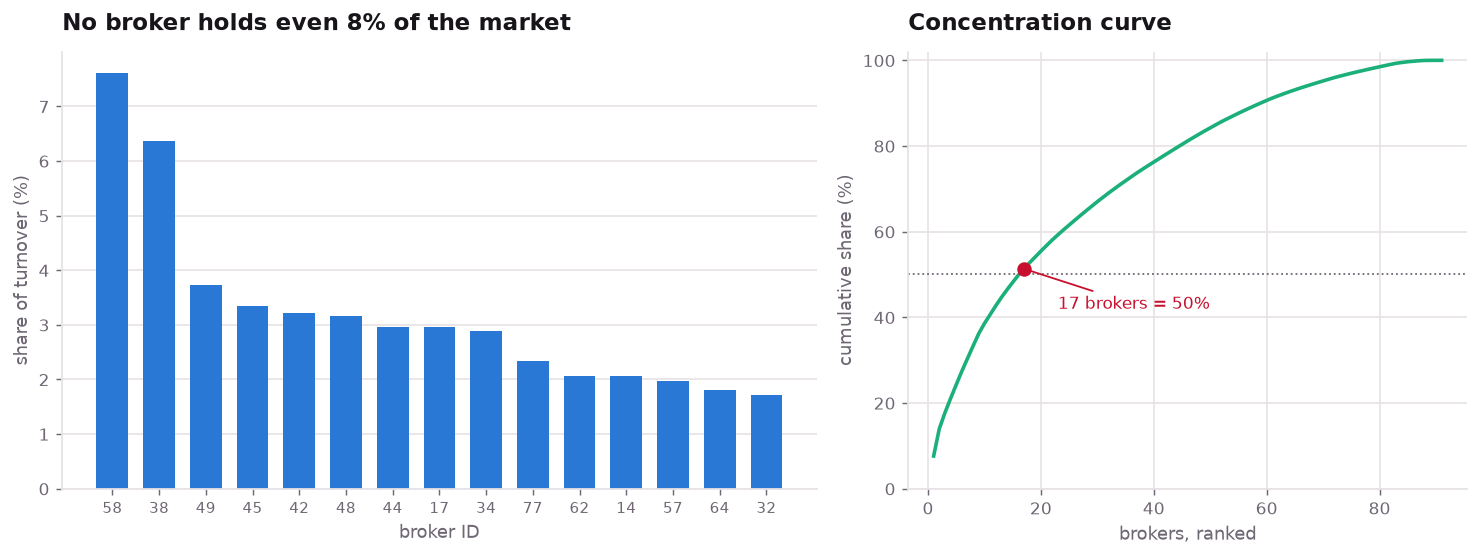

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1.35, 1]})

top = brokers.head(15)
ax1.bar(range(len(top)), top.pct, color=BLUE, width=0.68)
ax1.set_xticks(range(len(top)))
ax1.set_xticklabels(top.broker, fontsize=8.5)
ax1.set_ylabel("share of turnover (%)")
ax1.set_xlabel("broker ID")
ax1.set_title("No broker holds even 8% of the market")
ax1.grid(axis="x", visible=False)

cum = brokers.pct.cumsum().values
ax2.plot(range(1, len(cum) + 1), cum, color=AQUA, lw=2)
ax2.axhline(50, color=MUTED, lw=1, ls=":")
n50 = int(np.searchsorted(cum, 50)) + 1
ax2.plot([n50], [cum[n50 - 1]], "o", color=CRIMSON, ms=7)
ax2.annotate(f"{n50} brokers = 50%", xy=(n50, cum[n50 - 1]), xytext=(n50 + 6, 42),
             color=CRIMSON, fontsize=9.5,
             arrowprops=dict(arrowstyle="-", color=CRIMSON, lw=1))
ax2.set_xlabel("brokers, ranked")
ax2.set_ylabel("cumulative share (%)")
ax2.set_title("Concentration curve")
ax2.set_ylim(0, 102)

plt.tight_layout()
plt.show()

### Finding 1: NEPSE brokerage is competitive, not captured

An HHI in the low hundreds is a **fragmented, competitive** market. For reference,
US antitrust guidelines call anything under 1,500 unconcentrated; NEPSE sits far
below that. It takes well over a dozen firms to account for half of all turnover,
and the largest single broker handles under 8%.

This is worth stating because it contradicts a common assumption about frontier
markets. Whatever structural problems NEPSE has, brokerage capture is not
obviously one of them.

## 2. Does broker positioning persist?

Now the more interesting question. `broker_flow_daily` gives, for each broker and
symbol and day, buy value, sell value, and the signed net.

If brokers simply intermediate — matching customer buys against customer sells —
their net position should be close to random noise from day to day. If instead
they run **multi-day accumulation or distribution campaigns**, the sign of net
flow should persist.

The test: for every (broker, symbol) pair observed on consecutive sessions,
compare the sign of net value on day *t* with day *t+1*. A coin flip is 50%.

In [4]:
persistence = con.execute("""
    WITH d AS (
        SELECT broker_id, symbol, business_date, CAST(net_value AS DOUBLE) nv,
               row_number() OVER (PARTITION BY broker_id, symbol ORDER BY business_date) rn
        FROM broker_flow_daily
    ), pairs AS (
        SELECT a.nv AS nv_t, b.nv AS nv_t1
        FROM d a JOIN d b
          ON a.broker_id = b.broker_id AND a.symbol = b.symbol AND b.rn = a.rn + 1
    )
    SELECT
      CASE WHEN abs(nv_t) > 1000000 AND abs(nv_t1) > 1000000 THEN 'large (>1M NPR)'
           ELSE 'all positions' END AS bucket,
      count(*) n,
      avg(CASE WHEN sign(nv_t) = sign(nv_t1) THEN 1.0 ELSE 0 END) same_sign
    FROM pairs WHERE nv_t <> 0 AND nv_t1 <> 0 GROUP BY 1
    UNION ALL
    SELECT 'all positions (incl. small)', count(*),
           avg(CASE WHEN sign(nv_t) = sign(nv_t1) THEN 1.0 ELSE 0 END)
    FROM (
        SELECT a.nv nv_t, b.nv nv_t1 FROM d a JOIN d b
        ON a.broker_id=b.broker_id AND a.symbol=b.symbol AND b.rn=a.rn+1
    ) WHERE nv_t <> 0 AND nv_t1 <> 0
""").df()
print(persistence.to_string(index=False))

                     bucket     n  same_sign
              all positions 37727   0.573382
            large (>1M NPR)  1339   0.718447
all positions (incl. small) 39066   0.578355


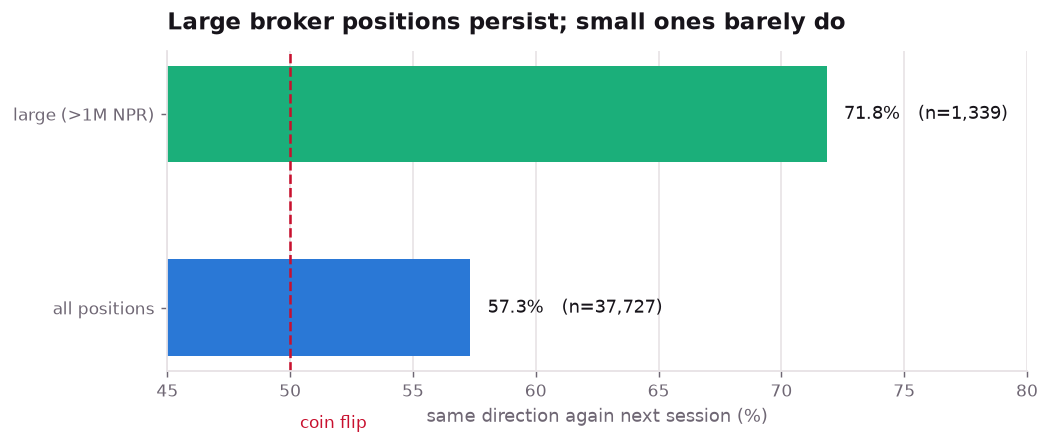

In [5]:
rows = persistence[persistence.bucket.isin(['all positions', 'large (>1M NPR)'])]
labels = list(rows.bucket)
vals = [v * 100 for v in rows.same_sign]
ns = list(rows.n)

fig, ax = plt.subplots(figsize=(8.2, 3.6))
bars = ax.barh(labels, vals, color=[BLUE, AQUA], height=0.5)
ax.axvline(50, color=CRIMSON, lw=1.4, ls="--")
ax.text(50.4, -0.62, "coin flip", color=CRIMSON, fontsize=9.3)
for b, v, n in zip(bars, vals, ns):
    ax.text(v + 0.7, b.get_y() + b.get_height()/2,
            f"{v:.1f}%   (n={n:,})", va="center", fontsize=10, color=INK)
ax.set_xlim(45, 80)
ax.set_xlabel("same direction again next session (%)")
ax.set_title("Large broker positions persist; small ones barely do")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### Finding 2: conviction persists, noise does not

Across all non-zero positions, the sign repeats about 58% of the time — a real
but modest tilt above chance. Restrict to positions above 1 million NPR and it
jumps to roughly **72%**.

That gap is the interesting part. It says the persistence is not a mechanical
artefact of the data; it is concentrated in exactly the positions where a broker
is doing something deliberate. Small flows look like intermediation. Large flows
look like campaigns that run over multiple days.

This is the kind of statement that is very hard to make on most exchanges,
because you cannot see who is on each side.

## 3. So does broker flow predict returns?

The obvious next step, and the one to be most careful with. We compare aggregate
large-broker net flow in a symbol against:

- the **same-day** return (close vs previous close), and
- the **next-day** return.

The first is a sanity check that the data means what we think it means. The second
is the question that would matter if you were trading.

In [6]:
pred = con.execute("""
    WITH flow AS (
        SELECT symbol, business_date, sum(CAST(net_value AS DOUBLE)) net_large
        FROM broker_flow_daily
        WHERE abs(CAST(net_value AS DOUBLE)) > 1000000
        GROUP BY 1, 2
    ), px AS (
        SELECT symbol, business_date,
               CAST(close_price AS DOUBLE) c,
               CAST(previous_day_close_price AS DOUBLE) pc,
               lead(CAST(close_price AS DOUBLE)) OVER (PARTITION BY symbol ORDER BY business_date) c_next
        FROM eod_price WHERE business_date >= DATE '2026-08-19'
    )
    SELECT 'same day' horizon, count(*) n,
           corr(f.net_large, (p.c - p.pc)/p.pc) correlation,
           avg(CASE WHEN sign(f.net_large) = sign(p.c - p.pc) THEN 1.0 ELSE 0 END) hit_rate
    FROM flow f JOIN px p USING (symbol, business_date) WHERE p.pc > 0
    UNION ALL
    SELECT 'next day', count(*),
           corr(f.net_large, (p.c_next - p.c)/p.c),
           avg(CASE WHEN sign(f.net_large) = sign(p.c_next - p.c) THEN 1.0 ELSE 0 END)
    FROM flow f JOIN px p USING (symbol, business_date)
    WHERE p.c_next IS NOT NULL AND p.c > 0
""").df()
print(pred.to_string(index=False))

 horizon   n  correlation  hit_rate
same day 904     0.316597  0.674779
next day 722    -0.034747  0.526316


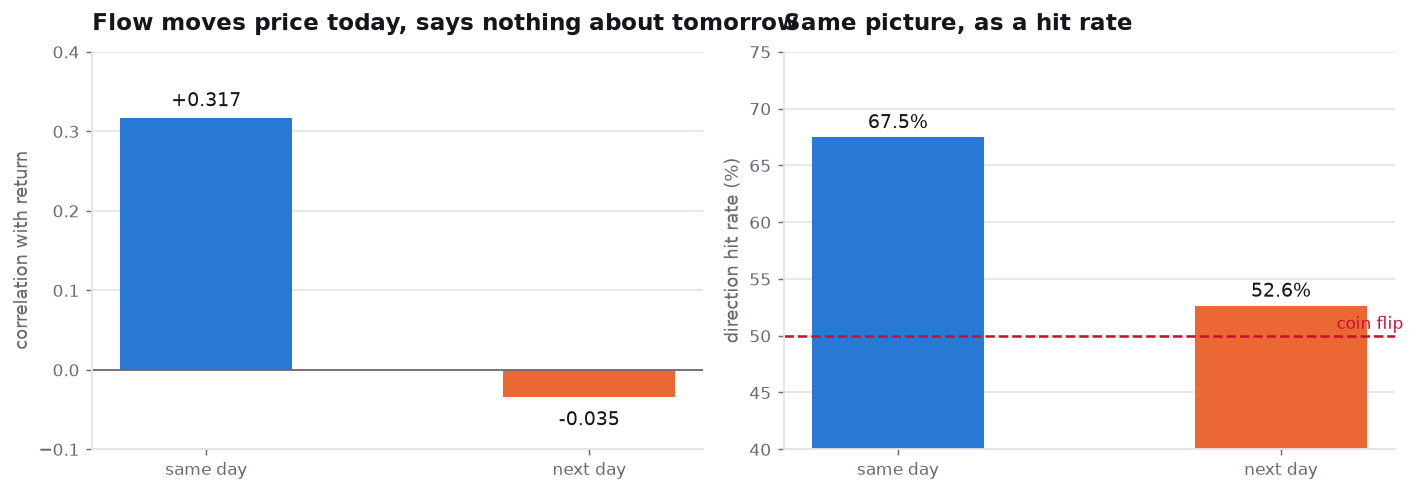

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.9))

ax1.bar(pred.horizon, pred.correlation, color=[BLUE, ORANGE], width=0.45)
ax1.axhline(0, color=MUTED, lw=1)
for i, v in enumerate(pred.correlation):
    ax1.text(i, v + (0.015 if v >= 0 else -0.035), f"{v:+.3f}", ha="center",
             fontsize=10.5, color=INK)
ax1.set_ylabel("correlation with return")
ax1.set_title("Flow moves price today, says nothing about tomorrow")
ax1.set_ylim(-0.1, 0.4)
ax1.grid(axis="x", visible=False)

ax2.bar(pred.horizon, pred.hit_rate * 100, color=[BLUE, ORANGE], width=0.45)
ax2.axhline(50, color=CRIMSON, lw=1.4, ls="--")
ax2.text(1.32, 50.6, "coin flip", color=CRIMSON, fontsize=9.3, ha="right")
for i, v in enumerate(pred.hit_rate * 100):
    ax2.text(i, v + 0.8, f"{v:.1f}%", ha="center", fontsize=10.5, color=INK)
ax2.set_ylim(40, 75)
ax2.set_ylabel("direction hit rate (%)")
ax2.set_title("Same picture, as a hit rate")
ax2.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

### Finding 3: strongly contemporaneous, no next-day edge

Same-day correlation of about **+0.32** with a 67% direction hit rate. That is
reassuring rather than exciting — it confirms the flow data is measuring what we
think. Net buying pressure and same-day price moves go together, which is close to
a definition.

Next-day correlation is **essentially zero**, and the hit rate is a coin flip.

**Do not read this as "broker flow contains no information."** With five sessions
and a few hundred usable observations, this test could only have detected a very
large effect. A realistic trading edge — say a 53% hit rate — would be invisible at
this sample size. The honest conclusion is *we cannot tell yet*, and the specific
thing that would change the answer is time: the archive grows by one session every
trading day, and none of it can be backfilled.

Anyone tempted to skip that caveat should notice how easy it would have been to
present the same-day number alone and imply a signal.

## Where this goes

The persistence result is the one worth building on. If large broker positions
really do run in multi-day campaigns, the natural follow-ups are:

- **Do campaigns cluster before news or corporate action announcements?**
- **Are some brokers systematically better?** Rank brokers by the forward return
  after their large positions — this needs a few hundred sessions to be credible.
- **Does the broker-to-broker network have structure?** Who consistently takes the
  other side of whom.

Every one of those needs history that only accrues going forward, which is exactly
why the capture pipeline runs unattended every trading day.

---

**Next:** [The corporate actions trap](02_corporate_actions.ipynb) — why every
price series in this dataset is quietly wrong, and how to find the damage.